# 02 - Model 2: CNN + TCN (dilated temporal convolutions) + CTC

Same CNN backbone, followed by 5 residual blocks of dilated 1-D convolutions (a temporal convolutional network). Dilations 1, 2, 4, 8, 16 give every output step a view of about 60 characters of context, like a recurrent network would, but all steps are computed in parallel, so it trains fast on a CPU. (The CNN + BiLSTM model was dropped because it was far too slow on a CPU.) Pipeline: `strip -> CNN -> TCN -> CTC -> text`.

**Run order:** notebook 00 first. Run this notebook top to bottom in one session.

In [1]:
import sys, json
sys.path.insert(0, ".")            # htr_data.py and htr_torch.py sit next to this notebook
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import htr_data as D
import htr_torch as T

cfg  = T.load_cfg()                # written by notebook 00
data = T.load_data(cfg)
(cfg["out"] / "figures").mkdir(exist_ok=True)
print("device :", T.get_device())
print("pages  :", {k: len(data[k]) for k in ("train", "val", "test")}, "| classes incl. blank:", T.n_classes(data))

device : cpu
pages  : {'train': 361, 'val': 87, 'test': 90} | classes incl. blank: 156


## 1. Settings

In [2]:
HEAD   = "tcn"
TAG    = "tcn"        # name of the saved model
DOWN   = 8         # time-axis downsampling of the backbone: 8 = half as many time steps as 4 = much faster
EPOCHS = 50       # you can stop the kernel at any time: the best checkpoint so far is already saved
LR     = 1e-3

## 2. Measure the speed first (about 1-2 minutes)

This prints the real seconds per batch and the projected minutes per epoch **before** you commit to a long run.
Small LSTM operations are often faster with fewer CPU threads, so a few thread counts are tried; the fastest one is used.

In [3]:
speeds = {}
for th in (2, 4, 8):
    speeds[th] = T.benchmark(HEAD, data, cfg, down=DOWN, n_batches=3, threads=th)
best_threads = min(speeds, key=speeds.get)
T.set_threads(best_threads)
print("using", best_threads, "CPU threads")

tcn         down=8 threads= 2 :   3.5 s/batch -> about   5.3 min per epoch (361 training pages)
tcn         down=8 threads= 4 :   2.1 s/batch -> about   3.2 min per epoch (361 training pages)
tcn         down=8 threads= 8 :   1.9 s/batch -> about   2.9 min per epoch (361 training pages)
using 8 CPU threads


## 3. Train

Best checkpoint = lowest **validation** CER. Early in training CER = 1.0 is normal; it should start dropping within roughly 10-25 epochs.

In [4]:
out = T.train_model(HEAD, data, cfg, epochs=EPOCHS, lr=LR, tag=TAG, down=DOWN)
print("best validation CER:", round(out["best_val_CER"], 4), "at epoch", out["best_epoch"], f"({out['minutes']:.1f} min)")

[tcn] device=cpu threads=8 down=8 params=2,746,748 train pages=361 val pages=87
[tcn] ep   1/50 | train 3.982 | val loss 3.079 | val CER 0.873 WER 0.999 | best 0.873 @ 1 | 3.5 min
[tcn] ep   2/50 | train 3.216 | val loss 2.844 | val CER 0.749 WER 1.010 | best 0.749 @ 2 | 7.4 min
[tcn] ep   3/50 | train 2.917 | val loss 2.651 | val CER 0.747 WER 0.982 | best 0.747 @ 3 | 11.5 min
[tcn] ep   4/50 | train 2.638 | val loss 2.573 | val CER 0.667 WER 0.994 | best 0.667 @ 4 | 15.9 min
[tcn] ep   5/50 | train 2.390 | val loss 2.266 | val CER 0.595 WER 0.950 | best 0.595 @ 5 | 19.6 min
[tcn] ep   6/50 | train 2.174 | val loss 2.178 | val CER 0.565 WER 0.938 | best 0.565 @ 6 | 23.9 min
[tcn] ep   7/50 | train 2.017 | val loss 2.022 | val CER 0.521 WER 0.926 | best 0.521 @ 7 | 27.8 min
[tcn] ep   8/50 | train 1.838 | val loss 1.905 | val CER 0.485 WER 0.871 | best 0.485 @ 8 | 31.6 min
[tcn] ep   9/50 | train 1.711 | val loss 1.883 | val CER 0.473 WER 0.885 | best 0.473 @ 9 | 35.1 min
[tcn] ep  10/

## 4. Training curves

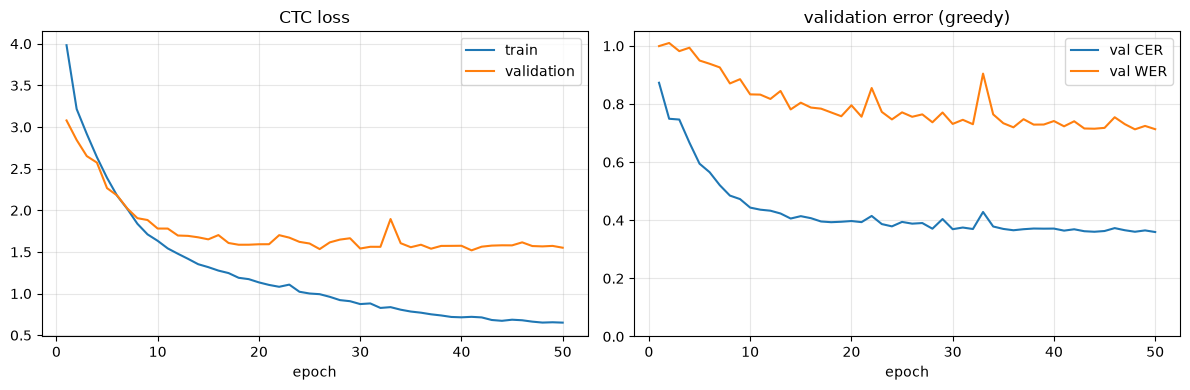

In [5]:
h = out["history"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation")
ax[0].set_title("CTC loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h.epoch, h.val_CER, label="val CER"); ax[1].plot(h.epoch, h.val_WER, label="val WER")
ax[1].set_ylim(0, 1.05); ax[1].set_title("validation error (greedy)"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(cfg["out"] / "figures" / f"{TAG}_training.png", dpi=150); plt.show()

## 5. Evaluate the best checkpoint on validation and test

In [6]:
model, res = T.evaluate_checkpoint(TAG, data, cfg)
r = T.save_result(TAG, HEAD, res, out, cfg, data)
print(pd.Series(r).to_string())

tag                   tcn
head                  tcn
down                    8
params            2746748
best_epoch             50
train_minutes       194.6
val_CER          0.359466
val_WER          0.713333
test_CER         0.230422
test_WER         0.612676
train_pages           361
val_pages              87
test_pages             90


In [7]:
te = res["test"]["df"]
for lang, g in te.groupby("language"):
    print(f"{lang:8s} pages={len(g):3d}  CER={D.corpus_cer(g.reference, g.prediction):.4f}  WER={D.corpus_wer(g.reference, g.prediction):.4f}")

print()
order = te.sort_values("CER").reset_index(drop=True)
for name, i in [("BEST", 0), ("MEDIAN", len(order) // 2), ("WORST", len(order) - 1)]:
    row = order.iloc[i]
    print(f"--- {name}  ({row.id}, {row.language})  CER {row.CER:.3f}")
    print("reference :", row.reference[:200])
    print("prediction:", row.prediction[:200])

Hindi    pages= 49  CER=0.2798  WER=0.6143
Marathi  pages= 41  CER=0.1840  WER=0.6106

--- BEST  (ma_850_110816, Marathi)  CER 0.094
reference : तुमचे काही चुकत असल्यास ते प्रेमळपणे तुम्हाला सल्ला देतात. नेवासे येथील उत्खननात तर अनेक जाती सापडल्या आहेत. आईनं आम्हा मुलांमध्ये ख्रिस्ती तत्त्वं रुजवण्याचा प्रयत्न केला. सध्या तो अमेरिकन इंटरनॅशनल 
prediction: तुमचे काही चुका असल्यास ते प्रमळपण तुम्हाला सला देतात. नेवासे ये थील उतखननात नर अनेक जाती सापडल्या आहेत. आईन आम्हा मुलामध्ये ख्िस्ती तत्वं रजवण्याचा प्रयन केला. सध्या तो अमेरिकन इंटरनैशनल युनिव्धरिंटी
--- MEDIAN  (hi_153_16013, Hindi)  CER 0.217
reference : या भूख के दिन रिश्तेदार यतीम या ख़ाकसार हरएक देश अपनी-अपनी जरूरतके मुताबिक रूई क्यों नहीं उगा सकता? इस स्थिति मे केन्द्र-राज्यों पर पूर्ण सम्प्रभु हो जाता है हम बस तुम्हारा थोड़ा सा मांस लेंगे। जन्म क
prediction: या भूरख के दिन िर्ेदार यती या एएाक देश अपनी अपनी जरतके मुतातिक रड क्यो नहीं उगा सक्ता, इस स्थित में बेन्ून राज्यो पर पूर्ण सम्रु हो जाता है हमग बस तुम्हारा योडा सा मास लें

**How to read the numbers.** CER = character errors / reference characters (0 = perfect, 1 = everything wrong, can exceed 1).
WER is the same on words and is always higher. What matters for the project is the *comparison between models* (notebook 04)
and that the result is honest (writer-disjoint test).